# Chapter 27: Auction Formats, Values, and Revenue Equivalence

This notebook reruns four worked examples from the chapter: one more bidder against the optimal reserve (Bulow-Klemperer), the winner's curse, revenue equivalence between first-price and second-price auctions, and affiliated signals. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def uniform_order_stat(k, n):
    """bulow-klemperer-theorem: expected k-th lowest of n uniform [0,1] draws, k / (n + 1).
    Book (ch027): second-highest of three is 2 / (3 + 1) = 1/2; lowest of two is 1/3."""
    return k / (n + 1)


def reserve_revenue_uniform_two(r=None):
    """bulow-klemperer-theorem: expected second-price revenue, two uniform [0,1] bidders, reserve r.
    Revenue = 2r(1 - r) r + (1 - r)^2 (r + (1 - r)/3). Book (ch027): r = 0.5 gives
    1/4 + 1/6 = 5/12 = 0.417; no reserve gives 1/3."""
    r = 0.0 if r is None else r
    one = 2 * r * (1 - r)
    both = (1 - r) ** 2
    low_mean = r + (1 - r) / 3
    return {"p_one": one, "p_both": both, "low_mean": low_mean, "from_one": one * r,
            "from_both": both * low_mean, "revenue": one * r + both * low_mean}


def max_discrete_error(values, n):
    """winners-curse-common-value-auction: distribution of the maximum of n independent errors,
    each equally likely over `values`. Counts are out of len(values)^n.
    Book (ch027): values (-20, 0, 20): n = 2 gives counts (1, 3, 5), mean 80/9 = 8.89;
    n = 3 gives (1, 7, 19), mean 360/27 = 13.33."""
    vals = sorted(values)
    m = len(vals)
    total = m ** n
    counts = [(i + 1) ** n - i ** n for i in range(m)]
    mean = sum(v * c for v, c in zip(vals, counts)) / total
    return {"values": vals, "counts": counts, "total": total, "probs": [c / total for c in counts], "mean": mean}


def first_price_bid_uniform2(v):
    """revenue-equivalence-theorem: symmetric first-price bid with two uniform bidders, b(v) = v / 2.
    Book (ch027): value 80 bids 40; expected revenue (1/2)(2(100)/3) = 33.33."""
    return v / 2


def second_price_payment(values):
    """revenue-equivalence-theorem: truthful second-price payment, the second-highest value.
    Book (ch027): values 80 and 50, the winner pays 50; E[min] = 100/3 = 33.33."""
    ordered = sorted(values, reverse=True)
    return ordered[1] if len(ordered) > 1 else 0.0


def bayes_2x2(joint):
    """affiliation: conditionals from a 2x2 joint table joint = ((P(H,H), P(H,L)), (P(L,H), P(L,L))),
    rows own signal, columns rival signal. Returns marginals and P(rival H | own H) and P(rival H | own L).
    Book (ch027): P(H,H) = P(L,L) = 0.40, off diagonal 0.10 gives P(H) = 0.50, 0.40 / 0.50 = 0.80
    and 0.10 / 0.50 = 0.20; the counterfactual (0.10, 0.40, 0.40, 0.10) gives 0.20 and 0.80."""
    (hh, hl), (lh, ll) = joint
    p_h, p_l = hh + hl, lh + ll
    return {"p_H": p_h, "p_L": p_l, "p_rival_H": hh + lh,
            "H_given_H": hh / p_h if p_h > 0 else None,
            "H_given_L": lh / p_l if p_l > 0 else None}


def affiliation_check(joint, tol=1e-12):
    """affiliation: discrete 2x2 check P(H,H) P(L,L) >= P(H,L) P(L,H).
    Book (ch027): 0.40(0.40) = 0.16 >= 0.10(0.10) = 0.01, affiliated; counterfactual 0.01 < 0.16 fails.
    Returns diagonal product, off-diagonal product, affiliated flag and independent flag (equality)."""
    (hh, hl), (lh, ll) = joint
    diag, off = hh * ll, hl * lh
    return {"diag": diag, "off": off, "affiliated": diag >= off - tol, "independent": abs(diag - off) <= tol}


plt.rcParams.update(HOUSE_RC)


auctions = SimpleNamespace(uniform_order_stat=uniform_order_stat, reserve_revenue_uniform_two=reserve_revenue_uniform_two, max_discrete_error=max_discrete_error, first_price_bid_uniform2=first_price_bid_uniform2, second_price_payment=second_price_payment)


information = SimpleNamespace(bayes_2x2=bayes_2x2, affiliation_check=affiliation_check)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'bulow-klemperer-theorem': {'reserve': 0.5,
                             'p_one': 0.5,
                             'from_one': 0.25,
                             'p_both': 0.25,
                             'low_mean': 0.6666666666666666,
                             'revenue_reserve': 0.4166666666666667,
                             'revenue_reserve_printed_as': 0.417,
                             'revenue_three': 0.5,
                             'gain': 0.08333333333333333,
                             'revenue_two_no_reserve': 0.3333333333333333,
                             'recruit_cost': 0.12,
                             'net_three': 0.38},
 'winners-curse-common-value-auction': {'mean_value': 100,
                                        'error': 20,
                                        'counts_2': [1, 3, 5],
                                        'mean_2': 8.88888888888889,
                                        'mean_2_printed_as': 8.89,
                                        'counts_3': [1, 7, 19],
                                        'mean_3': 13.333333333333334,
                                        'mean_3_printed_as': 13.33,
                                        'bid_2': 108.89,
                                        'bid_3': 113.33},
 'revenue-equivalence-theorem': {'high': 100,
                                 'values': [80, 50],
                                 'second_price_paid': 50,
                                 'first_price_paid': 40,
                                 'expected_revenue': 33.333333333333336,
                                 'expected_max': 66.66666666666667,
                                 'bidder_surplus': 16.67,
                                 'fee': 5,
                                 'with_fee': 43.333333333333336},
 'affiliation': {'joint': [[0.4, 0.1], [0.1, 0.4]],
                 'p_H': 0.5,
                 'H_given_H': 0.8,
                 'H_given_L': 0.2,
                 'diag': 0.16,
                 'off': 0.01,
                 'values': [50, 75, 100],
                 'value_given_H': 95,
                 'joint_cf': [[0.1, 0.4], [0.4, 0.1]]},
 'constructed': {'bulow-klemperer-theorem': {'recruit_cost': [0.05]},
                 'winners-curse-common-value-auction': {'n': [1, 4], 'error': [10, 30]},
                 'revenue-equivalence-theorem': {'high': [60, 100], 'low': [30]},
                 'affiliation': {'diagonal': [0.3, 0.25]}}}


def bk_picture(r="0.5", c=0):
    reserve = None if r == "none" else float(r)
    two = auctions.reserve_revenue_uniform_two(reserve)
    three = auctions.uniform_order_stat(2, 3)
    net = three - c
    diff = net - two["revenue"]
    winner, tie = tie_or_winner("three bidders", net, "two bidders", two["revenue"])
    fig, ax = new_figure()
    name2 = "Two bidders, reserve 0.5" if reserve else "Two bidders, no reserve"
    bar_compare(ax, [name2, "Three bidders, net of cost"], [two["revenue"], net],
                colors=["gold", "teal" if diff > 0 else "terracotta"],
                value_labels=[num(two["revenue"], 3), num(net, 3)], ylabel="Expected revenue (share of top value)",
                xlabel="Auction")
    ax.set_ylim(0, 0.62)
    label(ax, 0.5, 0.56, f"difference {plus(diff, 3)}", col="ink", ha="center", dx=0, dy=0)
    metrics = {"Two-bidder revenue": num(two["revenue"], 3), "Three-bidder gross revenue": num(three, 3),
               "Recruiting cost": num(c, 2), "Three-bidder net revenue": num(net, 3),
               "Better format": winner, "Break-even recruiting cost": num(three - two["revenue"], 3)}
    if reserve:
        two_txt = ("With reserve 0.5, one value clears it with probability 2(0.5)(0.5) = 0.50 and pays 0.5, giving "
                   "0.25; both clear it with probability 0.25 and the lower averages 2/3, giving 0.167. Revenue is "
                   "0.25 + 0.167 = 0.417.")
        two_steps = ["One above reserve: 0.50 x 0.5 = 0.25", "Both above: 0.25 x 2/3 = 0.167",
                     "Two-bidder revenue = 0.25 + 0.167 = 0.417"]
    else:
        two_txt = "Without a reserve, two bidders pay the expected lower value 1/(2 + 1) = 0.333."
        two_steps = ["Two-bidder revenue = 1 / 3 = 0.333"]
    interp = (two_txt + f" A third bidder with no reserve pays the expected second-highest of three, 2/(3 + 1) = 0.500; "
              f"net of a {num(c, 2)} recruiting cost that is 0.500 - {num(c, 2)} = {num(net, 3)}. The difference is "
              f"{num(net, 3)} - {num(two['revenue'], 3)} = {num(diff, 3)}, so "
              + ("the two formats tie." if tie else f"the {winner.replace(' bidders', '-bidder')} auction earns more."))
    steps = two_steps + [f"Three bidders: 2 / 4 = 0.500, net 0.500 - {num(c, 2)} = {num(net, 3)}",
                         f"Difference = {num(net, 3)} - {num(two['revenue'], 3)} = {num(diff, 3)}"]
    alt = (f"Two bars: the two-bidder auction earns {num(two['revenue'], 3)} and the three-bidder auction "
           f"{num(net, 3)} after a recruiting cost of {num(c, 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def curse_picture(n=2, e=20):
    res = auctions.max_discrete_error((-e, 0, e), n)
    c1, c2, c3 = res["counts"]
    T = res["total"]
    fig, (a1, a2) = new_figure(ncols=2)
    bar_compare(a1, [f"-{num(e, 0)}", "0", f"+{num(e, 0)}"], res["probs"], colors=["navy", "grey", "terracotta"],
                value_labels=[f"{c1}/{T}", f"{c2}/{T}", f"{c3}/{T}"], ylabel="Probability", xlabel="Largest error")
    a1.set_ylim(0, 1.08)
    ns = [1, 2, 3, 4]
    bids = [100 + auctions.max_discrete_error((-e, 0, e), k)["mean"] for k in ns]
    a2.plot(ns, bids, color=PALETTE["teal"], linewidth=2.2, marker="o")
    mark(a2, n, 100 + res["mean"], money(100 + res["mean"]), col="terracotta",
         dx=(8 if n <= 2 else -8), dy=8, ha=("left" if n <= 2 else "right"))
    hline(a2, 100, "true value $100", col="grey", x_frac=0.45, va="top")
    a2.set_xticks(ns)
    a2.set_xlim(0.6, 4.4)
    a2.set_ylim(95, 130)
    a2.set_xlabel("Number of bidders")
    a2.set_ylabel("Expected winning bid ($)")
    m = res["mean"]
    metrics = {"Expected largest error": money(m), "Expected naive winning bid": money(100 + m),
               "Expected winner payoff": money(-m), "Chance the largest error is +e": f"{c3}/{T}"}
    interp = (f"With {n} naive {'bidder' if n == 1 else 'bidders'} and errors of -{num(e, 0)}, 0 or +{num(e, 0)}, the "
              f"largest error is -{num(e, 0)} in {c1} of {T} cases, 0 in {c2} and +{num(e, 0)} in {c3}. So "
              f"E = (-{num(e, 0)}({c1}) + 0({c2}) + {num(e, 0)}({c3})) / {T} = {num(e * (c3 - c1), 0)} / {T} = {money(m)}. "
              f"The winner bids {money(100 + m)} on average for a lease worth $100, a payoff of {money(-m)}."
              + (" With one bidder there is no selection, so there is no curse." if n == 1 else ""))
    steps = [f"Counts out of {T}: {c1}, {c2}, {c3}",
             f"E = ({num(-e * c1, 0)} + 0 + {num(e * c3, 0)}) / {T} = {num(e * (c3 - c1), 0)} / {T} = {num(m)}",
             f"Winning bid = 100 + {num(m)} = {num(100 + m)}", f"Winner payoff = {num(-m)}"]
    alt = (f"Probability bars for the largest of {n} errors of size {num(e, 0)}, and the expected naive winning bid "
           f"rising with the number of bidders; at {n} it is {money(100 + m)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def re_picture(vh=80, vl=50, fee=0):
    sp_pay = auctions.second_price_payment([vh, vl])
    fp_pay = auctions.first_price_bid_uniform2(vh)
    sp_total = sp_pay + 2 * fee
    exp_sp, exp_fp = 100 / 3 + 2 * fee, 100 / 3
    winner, tie = tie_or_winner("second price", sp_total, "first price", fp_pay)
    fig, ax = new_figure()
    bar_compare(ax, ["Second price", "First price"], [sp_total, fp_pay], colors=["navy", "teal"],
                value_labels=[money(sp_total), money(fp_pay)], ylabel="Seller's receipts ($)", xlabel="Format")
    ax.set_ylim(0, 75)
    for t in ax.texts:  # keep value labels legible where the dashed expectation crosses them
        t.set_bbox(dict(facecolor="white", edgecolor="none", pad=1.0))
        t.set_zorder(5)
    ax.plot([-0.3, 0.3], [exp_sp, exp_sp], color=PALETTE["gold"], linewidth=2, linestyle="dashed")
    ax.plot([0.7, 1.3], [exp_fp, exp_fp], color=PALETTE["gold"], linewidth=2, linestyle="dashed")
    label(ax, 0.5, 68, f"dashed: expected {money(exp_sp)} and {money(exp_fp)}", col="gold", ha="center", dx=0, dy=0)
    who = "the two formats collect the same" if tie else f"{winner} collects more"
    metrics = {"Second-price receipts": money(sp_total), "First-price payment": money(fp_pay),
               "Expected revenue, second price": money(exp_sp), "Expected revenue, first price": money(exp_fp),
               "More in this draw": "tie" if tie else winner}
    fee_txt = (f" plus the entry fees 2 x {num(fee, 0)} = {num(2 * fee, 0)}, so it collects {num(sp_total, 0)}"
               if fee else "")
    interp = (f"With values {num(vh, 0)} and {num(vl, 0)}, the second-price winner pays the lower value {num(sp_pay, 0)}"
              f"{fee_txt}. The first-price winner bids {num(vh, 0)} / 2 = {num(fp_pay, 0)}. In this draw {who}. Before "
              f"values are known, both formats expect 100 / 3 = 33.33"
              + (f", and the fee adds 2 x {num(fee, 0)} = 10 to the second-price auction for 43.33, breaking the "
                 "equivalence." if fee else "."))
    steps = [(f"Second price collects {num(sp_pay, 0)} + 2 x {num(fee, 0)} = {num(sp_total, 0)}" if fee
              else f"Second price pays {num(sp_pay, 0)}"),
             f"First price pays {num(vh, 0)} / 2 = {num(fp_pay, 0)}",
             "Expected first price = (1/2)(2 x 100 / 3) = 33.33",
             ("Expected second price = 100 / 3 + 10 = 33.33 + 10 = 43.33" if fee
              else "Expected second price = 100 / 3 = 33.33")]
    alt = (f"Bars of realized receipts: second price {money(sp_total)}, first price {money(fp_pay)}, with expected "
           f"revenue lines at {money(exp_sp)} and {money(exp_fp)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def affiliation_picture(a=0.40):
    off = round(0.5 - a, 10)
    joint = ((a, off), (off, a))
    post = information.bayes_2x2(joint)
    chk = information.affiliation_check(joint)
    pHH = post["H_given_H"]
    value = pHH * 100 + (1 - pHH) * 75
    fig, (a1, a2) = new_figure(ncols=2)
    grid = [[a, off], [off, a]]
    a1.imshow(grid, cmap="Blues", vmin=0, vmax=0.6)
    for i in range(2):
        for j in range(2):
            a1.text(j, i, num(grid[i][j], 2), ha="center", va="center", fontsize=12,
                    color="white" if grid[i][j] > 0.3 else PALETTE["ink"])
    a1.set_xticks([0, 1], ["H", "L"])
    a1.set_yticks([0, 1], ["H", "L"])
    a1.set_xlabel("Rival's signal")
    a1.set_ylabel("Own signal")
    bar_compare(a2, ["Rival L", "Expected", "Rival H"], [75, value, 100], colors=["navy", "gold", "teal"],
                value_labels=["$75m", f"${num(value, 1)}m", "$100m"], ylabel="Tract value given own H ($m)",
                xlabel="Information")
    a2.set_ylim(0, 120)
    if chk["independent"]:
        status = "independent: the rival's signal carries no information"
    elif chk["affiliated"]:
        status = "affiliated"
    else:
        status = "negatively associated, not affiliated"
    cmp = ">=" if chk["affiliated"] else "<"
    metrics = {"P(rival H | own H)": num(pHH, 2), "P(rival H | own L)": num(post["H_given_L"], 2),
               "Expected value given own H": f"${num(value, 1)}m",
               "Affiliation check": f"{num(chk['diag'], 4)} {cmp} {num(chk['off'], 4)}", "Signals": status}
    interp = (f"P(rival H | own H) = {num(a, 2)} / 0.50 = {num(pHH, 2)}. A bidder with signal H expects "
              f"{num(pHH, 2)} x 100 + {num(1 - pHH, 2)} x 75 = {num(value, 1)} million. The check "
              f"{num(a, 2)} x {num(a, 2)} = {num(chk['diag'], 4)} {cmp} {num(off, 2)} x {num(off, 2)} = "
              f"{num(chk['off'], 4)} says the signals are {status}.")
    steps = [f"P(H | H) = {num(a, 2)} / 0.50 = {num(pHH, 2)}",
             f"Value = {num(pHH, 2)} x 100 + {num(1 - pHH, 2)} x 75 = {num(value, 1)}",
             f"Check: {num(chk['diag'], 4)} {cmp} {num(chk['off'], 4)}"]
    alt = (f"Joint probability grid with {num(a, 2)} on the diagonal and {num(off, 2)} off it, and the expected tract "
           f"value of {num(value, 1)} million for a bidder with a high signal.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Bulow-Klemperer theorem: one more bidder or the optimal reserve?

Values are uniform on 0 to 1, with virtual value $\phi(v)=2v-1$ and optimal reserve 0.5 for two bidders.

$$\frac14+\frac16=\frac{5}{12}\approx0.417, \qquad \frac{2}{3+1}=\frac12$$

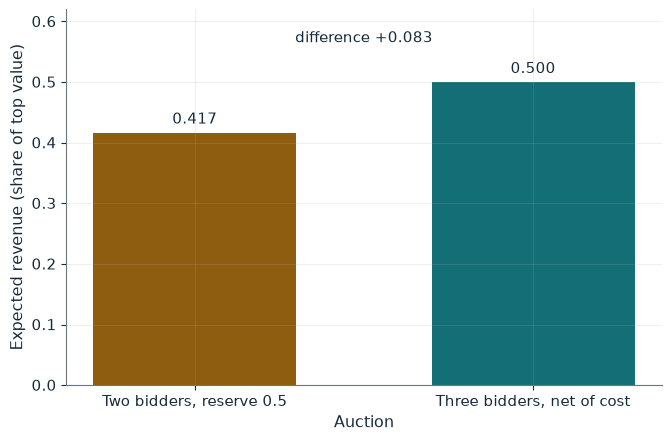

Two-bidder revenue          0.417
Three-bidder gross revenue  0.500
Recruiting cost             0.00
Three-bidder net revenue    0.500
Better format               three bidders
Break-even recruiting cost  0.083

Worked steps:
  1. One above reserve: 0.50 x 0.5 = 0.25
  2. Both above: 0.25 x 2/3 = 0.167
  3. Two-bidder revenue = 0.25 + 0.167 = 0.417
  4. Three bidders: 2 / 4 = 0.500, net 0.500 - 0.00 = 0.500
  5. Difference = 0.500 - 0.417 = 0.083

With reserve 0.5, one value clears it with probability 2(0.5)(0.5) = 0.50 and pays 0.5, giving 0.25; both clear it with probability 0.25 and the lower averages 2/3, giving 0.167. Revenue is 0.25 + 0.167 = 0.417. A third bidder with no reserve pays the expected second-highest of three, 2/(3 + 1) = 0.500; net of a 0.00 recruiting cost that is 0.500 - 0.00 = 0.500. The difference is 0.500 - 0.417 = 0.083, so the three-bidder auction earns more.


In [2]:
show(bk_picture(r='0.5', c=0))

Change one input, `c`, and hold the others at the book's values:

In [3]:
sweep(bk_picture, 'c', [0, 0.05, 0.12], {'r': '0.5'}, ['Two-bidder revenue', 'Three-bidder net revenue', 'Better format'])

c | Two-bidder revenue | Three-bidder net revenue | Better format
0 | 0.417 | 0.500 | three bidders
0.05 | 0.417 | 0.450 | three bidders
0.12 | 0.417 | 0.380 | two bidders


The third bidder adds 0.500 - 0.417 = 0.083 of expected revenue. A recruiting cost of 0.12 is larger than that, so the net ranking reverses.

## 2. The winner's curse in common-value auctions

Each bidder bids its signal $X_i=V+\varepsilon_i$ with errors of -\$20, \$0 or \$20.

$$E[\max_i\varepsilon_i\mid n=2]=\frac{-20(1)+0(3)+20(5)}{9}=\frac{80}{9}\approx\$8.89$$

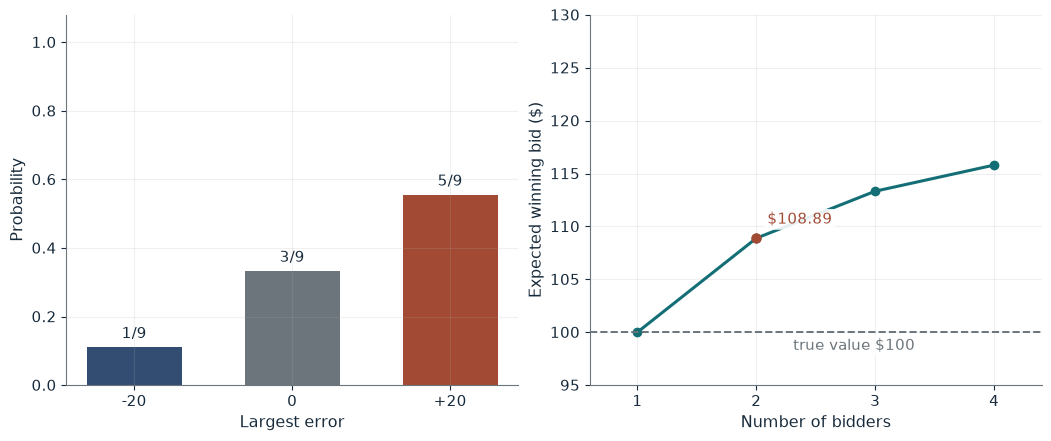

Expected largest error          $8.89
Expected naive winning bid      $108.89
Expected winner payoff          -$8.89
Chance the largest error is +e  5/9

Worked steps:
  1. Counts out of 9: 1, 3, 5
  2. E = (-20 + 0 + 100) / 9 = 80 / 9 = 8.89
  3. Winning bid = 100 + 8.89 = 108.89
  4. Winner payoff = -8.89

With 2 naive bidders and errors of -20, 0 or +20, the largest error is -20 in 1 of 9 cases, 0 in 3 and +20 in 5. So E = (-20(1) + 0(3) + 20(5)) / 9 = 80 / 9 = $8.89. The winner bids $108.89 on average for a lease worth $100, a payoff of -$8.89.


In [4]:
show(curse_picture(n=2, e=20))

Change one input, `n`, and hold the others at the book's values:

In [5]:
sweep(curse_picture, 'n', [1, 2, 3, 4], {'e': 20}, ['Expected largest error', 'Expected naive winning bid'])

n | Expected largest error | Expected naive winning bid
1 | $0.00 | $100.00
2 | $8.89 | $108.89
3 | $13.33 | $113.33
4 | $15.80 | $115.80


The naive winner overpays by \$8.89 with two bidders, \$13.33 with three and \$15.80 with four: more competition means a more optimistic winner.

## 3. Revenue-equivalence theorem

Two bidders, values uniform from \$0 to \$100; first-price bid $b(v)=v/2$.

$$E[\min(v_1,v_2)]=\frac{\$100}{3}\approx\$33.33, \qquad \frac{\$100}{3}+\$10=\frac{\$130}{3}\approx\$43.33$$

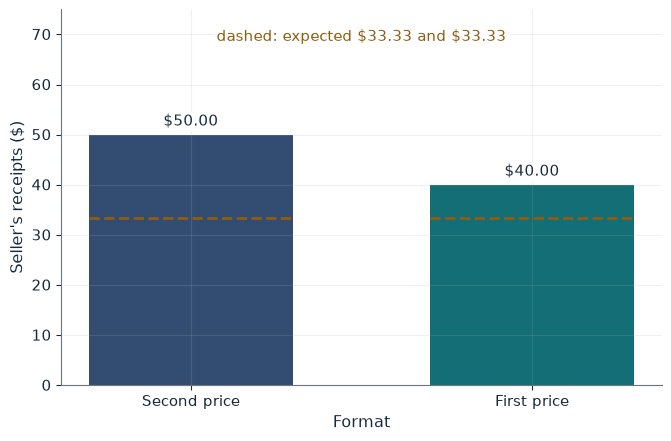

Second-price receipts           $50.00
First-price payment             $40.00
Expected revenue, second price  $33.33
Expected revenue, first price   $33.33
More in this draw               second price

Worked steps:
  1. Second price pays 50
  2. First price pays 80 / 2 = 40
  3. Expected first price = (1/2)(2 x 100 / 3) = 33.33
  4. Expected second price = 100 / 3 = 33.33

With values 80 and 50, the second-price winner pays the lower value 50. The first-price winner bids 80 / 2 = 40. In this draw second price collects more. Before values are known, both formats expect 100 / 3 = 33.33.


In [6]:
show(re_picture(vh=80, vl=50, fee=0))

Change one input, `vh`, and hold the others at the book's values:

In [7]:
sweep(re_picture, 'vh', [60, 80, 100], {'vl': 50, 'fee': 0}, ['Second-price receipts', 'First-price payment', 'More in this draw'])

vh | Second-price receipts | First-price payment | More in this draw
60 | $50.00 | $30.00 | second price
80 | $50.00 | $40.00 | second price
100 | $50.00 | $50.00 | tie


With values \$80 and \$50 the second-price auction collects \$50 and the first-price auction \$40, yet both expect \$33.33. The entry fee breaks the equivalence.

## 4. Affiliation

Joint signal probabilities 0.40 on the diagonal and 0.10 off it; the tract is worth \$50, \$75 or \$100 million.

$$\Pr(X_2=H\mid X_1=H)=\frac{0.40}{0.50}=0.80, \qquad 0.8(\$100)+0.2(\$75)=\$95\text{ million}$$

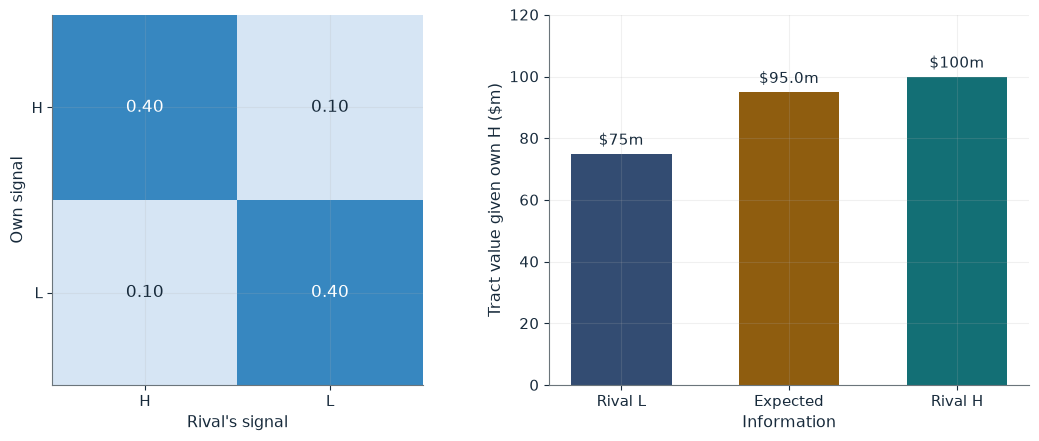

P(rival H | own H)          0.80
P(rival H | own L)          0.20
Expected value given own H  $95.0m
Affiliation check           0.1600 >= 0.0100
Signals                     affiliated

Worked steps:
  1. P(H | H) = 0.40 / 0.50 = 0.80
  2. Value = 0.80 x 100 + 0.20 x 75 = 95.0
  3. Check: 0.1600 >= 0.0100

P(rival H | own H) = 0.40 / 0.50 = 0.80. A bidder with signal H expects 0.80 x 100 + 0.20 x 75 = 95.0 million. The check 0.40 x 0.40 = 0.1600 >= 0.10 x 0.10 = 0.0100 says the signals are affiliated.


In [8]:
show(affiliation_picture(a=0.40))

Change one input, `a`, and hold the others at the book's values:

In [9]:
sweep(affiliation_picture, 'a', [0.4, 0.3, 0.25, 0.1], {}, ['P(rival H | own H)', 'Expected value given own H', 'Signals'])

a | P(rival H | own H) | Expected value given own H | Signals
0.4 | 0.80 | $95.0m | affiliated
0.3 | 0.60 | $90.0m | affiliated
0.25 | 0.50 | $87.5m | independent: the rival's signal carries no information
0.1 | 0.20 | $80.0m | negatively associated, not affiliated


With affiliated signals a high signal makes a rival's high signal likely and the bidder expects \$95 million. At 0.25 the signals are independent; at 0.10 they move in opposite directions.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

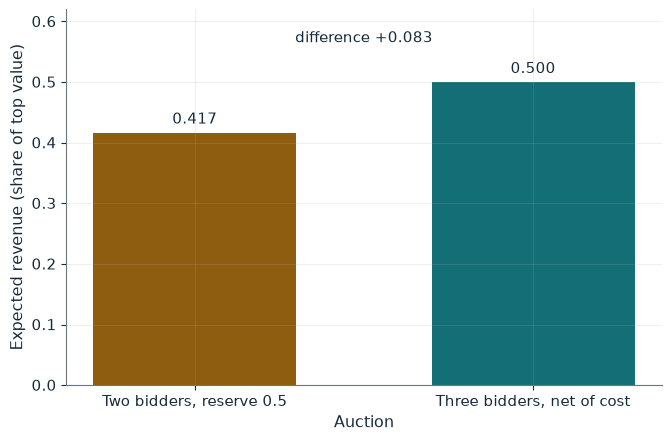

Two-bidder revenue          0.417
Three-bidder gross revenue  0.500
Recruiting cost             0.00
Three-bidder net revenue    0.500
Better format               three bidders
Break-even recruiting cost  0.083

Worked steps:
  1. One above reserve: 0.50 x 0.5 = 0.25
  2. Both above: 0.25 x 2/3 = 0.167
  3. Two-bidder revenue = 0.25 + 0.167 = 0.417
  4. Three bidders: 2 / 4 = 0.500, net 0.500 - 0.00 = 0.500
  5. Difference = 0.500 - 0.417 = 0.083

With reserve 0.5, one value clears it with probability 2(0.5)(0.5) = 0.50 and pays 0.5, giving 0.25; both clear it with probability 0.25 and the lower averages 2/3, giving 0.167. Revenue is 0.25 + 0.167 = 0.417. A third bidder with no reserve pays the expected second-highest of three, 2/(3 + 1) = 0.500; net of a 0.00 recruiting cost that is 0.500 - 0.00 = 0.500. The difference is 0.500 - 0.417 = 0.083, so the three-bidder auction earns more.


In [10]:
show(bk_picture(r='0.5', c=0))

## Practice

**1.** With a recruiting cost of 0.05, does the three-bidder auction still beat the optimal reserve?

<details><summary>Answer</summary>

0.50 - 0.05 = 0.45 > 5/12 = 0.417, yes; the break-even cost is 1/12 = 0.083.

</details>

**2.** With four naive bidders and errors of \$20, what is the expected overpayment?

<details><summary>Answer</summary>

Counts out of 81 are 1, 15 and 65; E = (-20 + 1,300) / 81 = 1,280 / 81 = \$15.80.

</details>

**3.** With values \$100 and \$30, which format collects more in that draw?

<details><summary>Answer</summary>

Second price collects 30, first price 100 / 2 = 50, so first price, though both expect \$33.33.

</details>